# 04 · Results: what do 16 tiles buy?

**The question:** how much better a detector we get from a 16-tile design (8×2, the
largest Tiny Tapeout slot) than from a smaller one, and which architecture uses the area
best.

**The ladder:**
* Each architecture is trained at 5 sizes, **~4× parameters apart**.
* The middle size is the one that fits ~16 tiles in total, by the cost model in notebook 02.
* The **tiles** column is the estimated tile equivalent of the whole chip: front end (~5) +
  classifier engine (~2) + on-chip state. Tiles don't scale 4× with parameters, because
  the weights live off-chip in the QSPI flash and the front end is a fixed cost.
* **qspi_load** is the fraction of the QSPI bus the weights (and any external state) need.
  Above 1.0 the model doesn't fit at 8-bit weights.

**The metrics** (all on held-out data, chosen without ever looking at the test half):
* `frr_syn@1.0`: missed **TTS** keywords at 1 false alarm/h on held-out simulated
  conversation.
* `frr_real@1.0`: missed **real** keywords (Common Voice speakers, real rooms) at that same
  threshold.
* `fa_real_ami@1.0`: false alarms/h on **86 h of real meetings** at that threshold. The
  simulator is calibrated if this is ≈ 1.
* `frr_real@real1`: missed real keywords with the threshold set on the *real* streams at
  1 FA/h. **This is the number that matters**: real speakers, real false-alarm rate.

**Status log** (newest first)

| date | what | outcome |
|---|---|---|
| 2026-10-26 | GPU (ROCm) trainer; 4 architectures × 5 sizes; early stopping on a simulator holdout split from the test half | running, telescope first |
| 2026-10-26 | Training cache: 16 mixes per keyword clip (was 2), ±10% speed | fixed the overfitting that made long runs worse |
| 2026-10-26 | Validation with best-checkpoint selection | showed the 12k-step collapse was memorising ~4k positive windows |
| 2026-10-25 | Hard-negative mining + feature augmentation (CPU GRU H32) | frr_real@real1 0.81 → 0.72 |
| 2026-10-24 | First sim-vs-real calibration | real meetings false-alarm 0.67× the sim rate (sim is pessimistic) |

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from nbutil import ARCH_COLOR, ARCH_ORDER, TILE_BUDGET, load_runs, progress, table

runs = load_runs()
df = table(runs)
progress()
pd_opts = {"display.width": 250, "display.max_columns": 30, "display.precision": 3}
import pandas as pd  # noqa: E402

with pd.option_context(*[x for kv in pd_opts.items() for x in kv]):
    display(df) if len(df) else print("no finished runs yet")

telescope_gru            gru:43 step 2500 train 0.879 val_loss 0.432 val_score 0.873 real 0.897 ami 0.00/h (368s) *
telescope_mingru         mingru:86 step 1250 train 1.354 val_loss 1.013 val_score 1.000 real 1.000 ami 0.00/h (79s)
telescope_tcn            tcn:16 step 2000 train 0.990 val_loss 0.666 val_score 0.833 real 0.915 ami 0.40/h (345s)
telescope_transformer    transformer:10 step 7250 train 0.955 val_loss 0.528 val_score 0.824 real 0.920 ami 0.00/h (368s)


,slug,arch,size_index,width,params,tiles,classifier_tiles,qspi_load,best_step,stopped_step,train_time_s,frr_syn@1.0,frr_real@1.0,fa_real_ami@1.0,frr_syn@real1,frr_real@real1
0,telescope,mingru,0,43,5290,9.6,4.6,0.08,4250,6250,287.2,1.0,1.0,0.0,1.0,1.0


## Accuracy vs size

Left: missed real keywords against parameters (the 4× ladder). Right: the same against
estimated **tiles**; the shaded area is beyond the 16-tile maximum. Open markers need
more QSPI bandwidth than the bus has at 8-bit weights (they'd need 4-bit weights or a
slower frame rate).

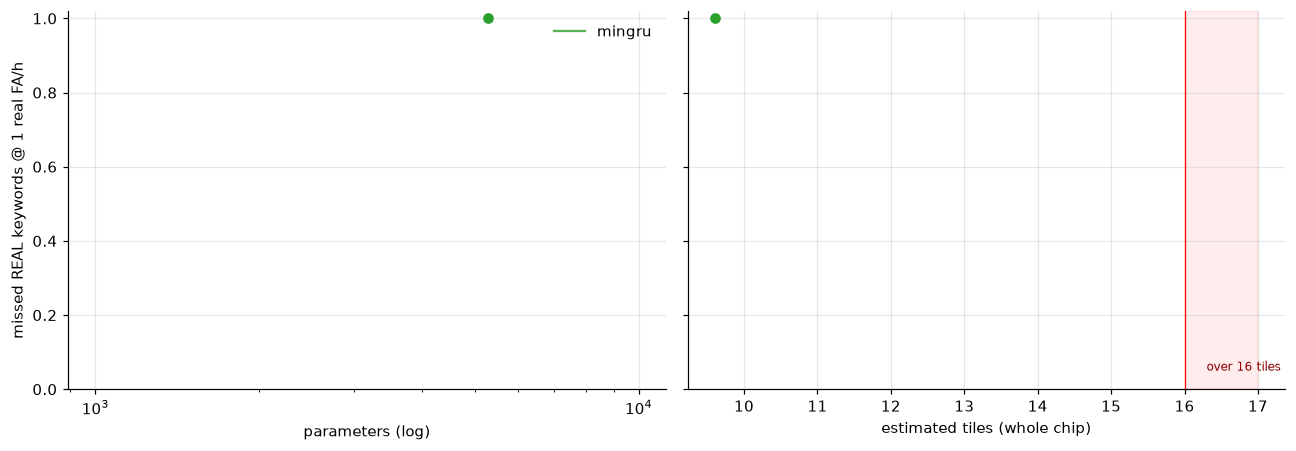

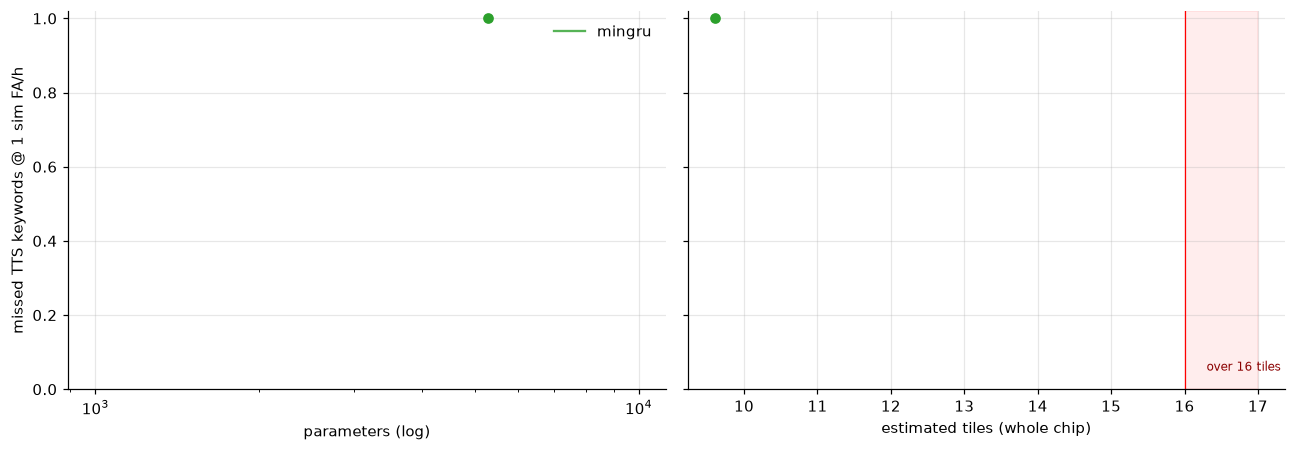

In [2]:
def size_plot(metric, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
    for w in sorted(df["slug"].unique()):
        d = df[df["slug"] == w]
        for a in ARCH_ORDER:
            e = d[d["arch"] == a].sort_values("params")
            if e.empty:
                continue
            for ax, x in zip(axes, ("params", "tiles")):
                ax.plot(e[x], e[metric], "-", color=ARCH_COLOR[a], alpha=0.8, label=a if w == d["slug"].iloc[0] else None)
                fits = e["qspi_load"] <= 1
                ax.plot(e[x][fits], e[metric][fits], "o", color=ARCH_COLOR[a])
                ax.plot(e[x][~fits], e[metric][~fits], "o", mfc="white", color=ARCH_COLOR[a])
    axes[0].set(xscale="log", xlabel="parameters (log)", ylabel=title, ylim=(0, 1.02))
    axes[1].set(xlabel="estimated tiles (whole chip)")
    axes[1].axvspan(TILE_BUDGET, max(TILE_BUDGET + 1, df["tiles"].max() + 1), color="red", alpha=0.07)
    axes[1].axvline(TILE_BUDGET, color="red", lw=0.8)
    axes[1].text(TILE_BUDGET + 0.3, 0.05, "over 16 tiles", color="darkred", fontsize=8)
    axes[0].legend()
    plt.tight_layout()


if len(df):
    size_plot("frr_real@real1", "missed REAL keywords @ 1 real FA/h")
    size_plot("frr_syn@1.0", "missed TTS keywords @ 1 sim FA/h")

## The benefit of 16 tiles

For each tile budget, the best model that fits it (tiles ≤ budget and QSPI load ≤ 1),
taken over all architectures.

In [3]:
if len(df):
    ok = df[df["qspi_load"] <= 1]
    rows = []
    for w in sorted(df["slug"].unique()):
        for budget in (8, 10, 12, 14, 16, 24, 999):
            d = ok[(ok["slug"] == w) & (ok["tiles"] <= budget)]
            if d.empty:
                continue
            b = d.loc[d["frr_real@real1"].idxmin()]
            rows.append({"word": w, "tile budget": "any" if budget == 999 else budget, "best arch": b["arch"],
                         "params": int(b["params"]), "tiles": b["tiles"], "frr_real@real1": round(b["frr_real@real1"], 3),
                         "frr_syn@1.0": round(b["frr_syn@1.0"], 3)})
    display(pd.DataFrame(rows))

,word,tile budget,best arch,params,tiles,frr_real@real1,frr_syn@1.0
0,telescope,10,mingru,5290,9.6,1.0,1.0
1,telescope,12,mingru,5290,9.6,1.0,1.0
2,telescope,14,mingru,5290,9.6,1.0,1.0
3,telescope,16,mingru,5290,9.6,1.0,1.0
4,telescope,24,mingru,5290,9.6,1.0,1.0
5,telescope,any,mingru,5290,9.6,1.0,1.0


## Is the simulator honest?

At the threshold set on simulated conversation (1 FA/h):

* **Left:** FA/h on 86 h of real meetings. Near 1 means the simulator predicts real false
  alarms; below 1 means the sim is pessimistic (safe).
* **Right:** real-speaker FRR vs TTS FRR. Above the diagonal, real voices are harder than
  the TTS voices we train on.

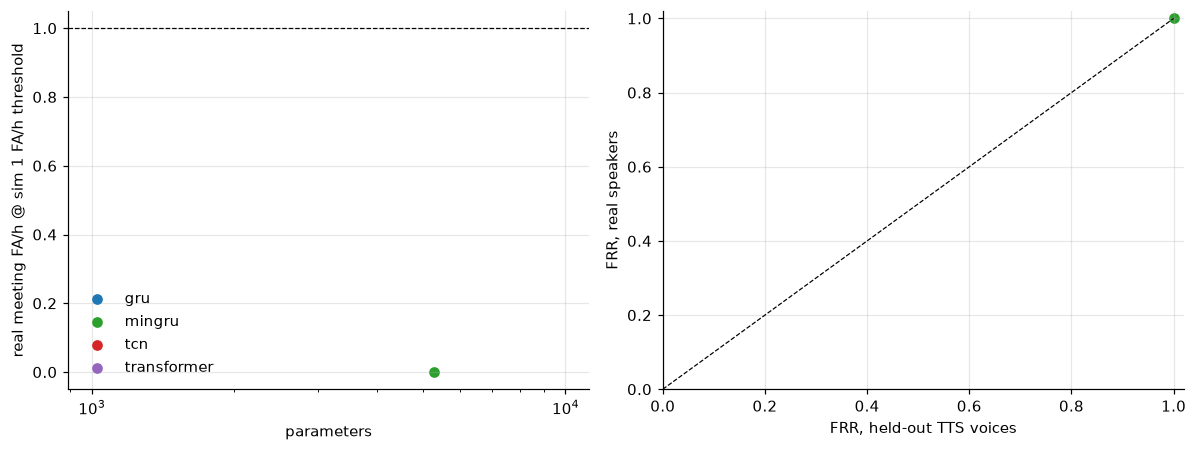

In [4]:
if len(df):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    for a in ARCH_ORDER:
        d = df[df["arch"] == a]
        axes[0].scatter(d["params"], d["fa_real_ami@1.0"], color=ARCH_COLOR[a], label=a)
        axes[1].scatter(d["frr_syn@1.0"], d["frr_real@1.0"], color=ARCH_COLOR[a], label=a)
    axes[0].axhline(1, color="k", lw=0.8, ls="--")
    axes[0].set(xscale="log", xlabel="parameters", ylabel="real meeting FA/h @ sim 1 FA/h threshold")
    axes[1].plot([0, 1], [0, 1], "k--", lw=0.8)
    axes[1].set(xlabel="FRR, held-out TTS voices", ylabel="FRR, real speakers", xlim=(0, 1.02), ylim=(0, 1.02))
    axes[0].legend()
    plt.tight_layout()